# 🍺 Lab 2: previsão hierárquica de vendas de cerveja

**Financial Analytics, PADS Insper 2026** · Julio Trecenti e Paloma Vaissman Uribe

<a href="https://colab.research.google.com/github/padsInsper/202634-fa/blob/main/complementar/lab02-hierarquicas-exercicio.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

***

## Objetivo

Praticar as duas ideias da exposição numa base com cara de empresa:

1. **Modelos diferentes** para as mesmas séries: um baseline ingênuo, um modelo estatístico
   por série (ETS) e um modelo de machine learning **global** (LightGBM, um modelo só para
   todas as séries).
2. **Formas diferentes de tratar a hierarquia**: usar as previsões de cada nível como estão,
   ou reconciliá-las com bottom-up, top-down e MinT.

## O caso

A **Cervejaria Ipê** (fictícia) vende cerveja nas cinco regiões do Brasil. O planejamento
precisa da previsão de **2025, mês a mês**, em quatro níveis:

| Nível | Quem usa | Séries |
|---|---|---|
| Brasil | diretoria (orçamento) | 1 |
| Região | gerentes regionais | 5 |
| Região × categoria | marketing | 20 |
| Região × categoria × SKU | logística e fábrica | 50 |

As vendas estão em **milhares de litros por mês**, de jan/2018 a dez/2025. Usamos
2018 a 2024 para treinar e **guardamos 2025 como teste**.

## Roteiro (cerca de 45 minutos, em grupo)

1. Rodem o notebook inteiro (**Ambiente de execução → Executar tudo**) e leiam as saídas: 10 min.
2. Respondam às **perguntas** marcadas com 🧩 ao longo do caminho: 20 min.
3. Façam **uma** das modificações da seção final e vejam o efeito: 15 min.
4. Mandem no chat a modificação feita e a **combinação vencedora** no nível SKU depois dela (ver o fim do notebook).

## 0. Instalação

No Colab, rode a célula abaixo uma vez (leva cerca de 1 minuto). Se o Colab avisar que o
notebook não é do Google, clique em **Executar mesmo assim**; se pedir para reiniciar a sessão
depois da instalação, reinicie e rode tudo de novo. Localmente, use o ambiente do curso e
acrescente `hierarchicalforecast`.

In [ ]:
%pip install -q "hierarchicalforecast>=1.5,<1.6" "statsforecast>=2,<3" "mlforecast>=1,<2"

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

VERMELHO, TURQUESA, ROXO, LARANJA, AZUL, CINZA = (
    "#E50505", "#12996F", "#730D9F", "#C96A10", "#1F63C6", "#5B5B5B")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)

URL = "https://raw.githubusercontent.com/padsInsper/202634-fa/main/dados/cerveja_vendas.csv"
vendas = pd.read_csv(URL, parse_dates=["data"])
vendas.head()

,data,regiao,categoria,sku,vendas
0,2018-01-01,Sudeste,Pilsen,PIL-LT350,9544.4
1,2018-02-01,Sudeste,Pilsen,PIL-LT350,9354.9
2,2018-03-01,Sudeste,Pilsen,PIL-LT350,9633.4
3,2018-04-01,Sudeste,Pilsen,PIL-LT350,8579.2
4,2018-05-01,Sudeste,Pilsen,PIL-LT350,7416.8


## 1. Conhecendo a base

Cada linha é **um SKU, numa região, num mês**. Só esse nível mais baixo existe na base:
os totais (por categoria, por região, Brasil) são **somas** dele.

In [3]:
print(f"{len(vendas)} linhas, de {vendas.data.min():%m/%Y} a {vendas.data.max():%m/%Y}")
print(f"{vendas.groupby(['regiao', 'sku']).ngroups} séries no nível mais baixo\n")
vendas.groupby(["categoria", "sku"]).vendas.mean().round(0).to_frame("média mensal (mil litros)")

4300 linhas, de 01/2018 a 12/2025
50 séries no nível mais baixo



média mensal (mil litros)
categoria  sku                                 
Pilsen     PIL-GF600                     2486.0
           PIL-LT350                     3848.0
           PIL-LT473                     1667.0
Premium    PR-GF600                       566.0
           PR-LN330                       958.0
Puro malte PM-LN355                       918.0
           PM-LT350                      1705.0
           PM-LT473                       919.0
Sem álcool SA-LN355                       281.0
           SA-LT350                       517.0

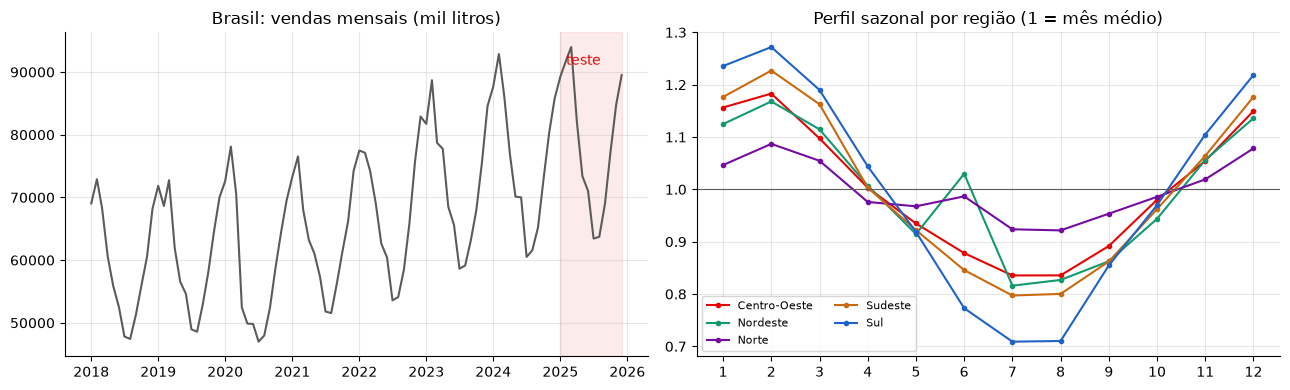

In [4]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

# o total do Brasil, com o ano de teste destacado
brasil = vendas.groupby("data").vendas.sum()
eixos[0].plot(brasil.index, brasil.values, color=CINZA)
eixos[0].axvspan(pd.Timestamp("2025-01-01"), brasil.index.max(), color=VERMELHO, alpha=0.08)
eixos[0].text(pd.Timestamp("2025-02-01"), brasil.max() * 0.97, "teste", color=VERMELHO)
eixos[0].set_title("Brasil: vendas mensais (mil litros)")

# o perfil sazonal de cada região: cada mês dividido pela média do ano
cores = [VERMELHO, TURQUESA, ROXO, LARANJA, AZUL]
por_regiao = vendas.groupby(["regiao", "data"]).vendas.sum().reset_index()
por_regiao["indice"] = por_regiao.vendas / por_regiao.groupby(
    ["regiao", por_regiao.data.dt.year]).vendas.transform("mean")
perfil = por_regiao.groupby(["regiao", por_regiao.data.dt.month]).indice.mean().unstack(0)
for cor, regiao in zip(cores, perfil.columns):
    eixos[1].plot(perfil.index, perfil[regiao], marker="o", ms=3, color=cor, label=regiao)
eixos[1].axhline(1, color=CINZA, lw=0.8)
eixos[1].set_xticks(range(1, 13))
eixos[1].set_title("Perfil sazonal por região (1 = mês médio)")
eixos[1].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

🧩 **Pergunta 1.** Olhem o perfil sazonal. Que região tem um pico **fora do verão**? Que região
quase não tem sazonalidade? O `TopDown` deste notebook reparte o Brasil pelas proporções das
**próprias previsões** de cada série (`forecast_proportions`), e não por uma proporção histórica
fixa: ele preservaria o pico de junho? Confiram no gráfico da seção 5.

## 2. Montando a hierarquia

A função `aggregate` recebe o nível mais baixo e uma **especificação** dos níveis, e devolve três coisas:

- `Y_df`: todas as séries, de todos os níveis, empilhadas no formato longo (`unique_id`, `ds`, `y`);
- `S_df`: a **matriz de soma** $S$, que diz quais séries de baixo somam cada série;
- `tags`: o dicionário que diz quais `unique_id` pertencem a cada nível.

In [5]:
from hierarchicalforecast.utils import aggregate

vendas["total"] = "Brasil"
base = vendas.rename(columns={"data": "ds", "vendas": "y"})

spec = [
    ["total"],
    ["total", "regiao"],
    ["total", "regiao", "categoria"],
    ["total", "regiao", "categoria", "sku"],
]
Y_df, S_df, tags = aggregate(base[["total", "regiao", "categoria", "sku", "ds", "y"]], spec)

for nivel, ids in tags.items():
    print(f"{nivel:30s} {len(ids):3d} séries, ex.: {ids[0]}")
print(f"\nMatriz S: {S_df.shape[0]} séries (linhas) x {S_df.shape[1] - 1} séries de base (colunas)")

total                            1 séries, ex.: Brasil
total/regiao                     5 séries, ex.: Brasil/Centro-Oeste
total/regiao/categoria          20 séries, ex.: Brasil/Centro-Oeste/Pilsen
total/regiao/categoria/sku      50 séries, ex.: Brasil/Centro-Oeste/Pilsen/PIL-GF600

Matriz S: 76 séries (linhas) x 50 séries de base (colunas)


In [6]:
# um pedaço da matriz S: as linhas do Brasil e de duas regiões, as primeiras colunas da base
S_df.set_index("unique_id").iloc[:3, :6].astype(int)

,Brasil/Centro-Oeste/Pilsen/PIL-GF600,Brasil/Centro-Oeste/Pilsen/PIL-LT350,Brasil/Centro-Oeste/Pilsen/PIL-LT473,Brasil/Centro-Oeste/Premium/PR-GF600,Brasil/Centro-Oeste/Premium/PR-LN330,Brasil/Centro-Oeste/Puro malte/PM-LN355
unique_id,,,,,,
Brasil,1,1,1,1,1,1
Brasil/Centro-Oeste,1,1,1,1,1,1
Brasil/Nordeste,0,0,0,0,0,0


🧩 **Pergunta 2.** Quantos "1" tem a linha `Brasil` da matriz $S$? E a linha de uma região? Por quê?

In [7]:
H = 12  # meses à frente
treino = Y_df[Y_df.ds < "2025-01-01"]
teste = Y_df[Y_df.ds >= "2025-01-01"]
print(f"treino: {treino.ds.min():%m/%Y} a {treino.ds.max():%m/%Y} | teste: {teste.ds.min():%m/%Y} a {teste.ds.max():%m/%Y}")

treino: 01/2018 a 12/2024 | teste: 01/2025 a 12/2025


## 3. Previsões de base: três modelos para as 76 séries

Prevemos **cada série de cada nível** separadamente (as previsões "de base"):

- `SeasonalNaive`: repete o mesmo mês do ano anterior. É o baseline.
- `AutoETS`: um modelo de suavização exponencial **por série**, escolhido por AICc.
- `LightGBM`: **um modelo global**, treinado com as 76 séries ao mesmo tempo, com lags,
  médias móveis e o mês como features. Para as séries de escalas tão diferentes caberem no
  mesmo modelo, cada uma é diferenciada sazonalmente e padronizada antes. Repare que ele
  mistura séries de níveis diferentes (o Brasil e os SKUs) no mesmo treino.

Guardamos também os valores ajustados dentro da amostra (`fitted`): o MinT usa os erros
dentro da amostra para saber em que séries confiar mais. Cuidado: os ajustes de árvores
dentro da amostra são otimistas, então o `mint_shrink` tende a confiar demais no LightGBM.

In [8]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive, AutoETS

sf = StatsForecast(models=[SeasonalNaive(season_length=12), AutoETS(season_length=12)],
                   freq="MS", n_jobs=1)
prev_sf = sf.forecast(df=treino, h=H, fitted=True)
ajuste_sf = sf.forecast_fitted_values()
prev_sf.head(3)

,unique_id,ds,SeasonalNaive,AutoETS
0,Brasil,2025-01-01,87663.4,87026.065122
1,Brasil,2025-02-01,92869.3,89665.350720
2,Brasil,2025-03-01,86175.3,84544.571042


In [9]:
from mlforecast import MLForecast
from mlforecast.lag_transforms import RollingMean
from mlforecast.target_transforms import Differences, LocalStandardScaler
from lightgbm import LGBMRegressor

mlf = MLForecast(
    models={"LightGBM": LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15,
                                      verbose=-1, random_state=1)},
    freq="MS",
    lags=[1, 2, 3, 12],                                   # y de 1, 2, 3 e 12 meses atrás
    lag_transforms={1: [RollingMean(window_size=3),       # médias móveis que terminam em t-1
                        RollingMean(window_size=12)]},
    date_features=["month"],                              # o mês como feature
    target_transforms=[Differences([12]), LocalStandardScaler()],
)
mlf.fit(treino, fitted=True)
prev_ml = mlf.predict(h=H)
ajuste_ml = mlf.forecast_fitted_values()

# a "tabela" que o LightGBM enxerga, para uma série (já diferenciada e padronizada)
mlf.preprocess(treino).query("unique_id == 'Brasil'").tail(3)

,unique_id,ds,y,lag1,lag2,lag3,lag12,rolling_mean_lag1_window_size3,rolling_mean_lag1_window_size12,month
81,Brasil,2024-10-01,0.546670,-0.192914,-0.093350,-0.233021,-0.155385,-0.173095,-0.010718,10
82,Brasil,2024-11-01,0.481587,0.546670,-0.192914,-0.093350,-0.750037,0.086802,0.047787,11
83,Brasil,2024-12-01,-0.404127,0.481587,0.546670,-0.192914,-0.283129,0.278448,0.150422,12


🧩 **Pergunta 3.** Na tabela acima, que colunas são features e qual é o alvo? Alguma delas usa
informação do próprio mês `ds` (o que seria vazamento)?

In [10]:
prev = prev_sf.merge(prev_ml, on=["unique_id", "ds"])
ajuste = ajuste_sf.merge(ajuste_ml.drop(columns="y"), on=["unique_id", "ds"]).dropna()
MODELOS = ["SeasonalNaive", "AutoETS", "LightGBM"]

# as previsões de base somam? O total de 2025 do Brasil direto, das 5 regiões e dos 50 SKUs
p = prev.set_index(["unique_id", "ds"])
brasil_direto = p.loc["Brasil"][MODELOS].sum()
soma_regioes = p.loc[tags["total/regiao"]].groupby("ds")[MODELOS].sum().sum()
soma_skus = p.loc[tags["total/regiao/categoria/sku"]].groupby("ds")[MODELOS].sum().sum()
pd.DataFrame({"Brasil direto": brasil_direto,
              "soma das 5 regiões": soma_regioes,
              "soma dos 50 SKUs": soma_skus,
              "SKUs vs. Brasil (%)": 100 * (soma_skus / brasil_direto - 1)}).round(1)

,Brasil direto,soma das 5 regiões,soma dos 50 SKUs,SKUs vs. Brasil (%)
SeasonalNaive,910024.3,910024.3,910024.3,0.0
AutoETS,906739.6,910441.7,932599.6,2.9
LightGBM,937643.5,942003.0,954811.5,1.8


🧩 **Pergunta 4.** Em que modelo a soma dos SKUs fica mais longe do Brasil direto? Por que um
dos três soma perfeitamente mesmo sem reconciliar? (Dica: pensem no que o `SeasonalNaive` faz.)

## 4. Reconciliação

Agora tornamos as previsões **coerentes** de quatro jeitos, para cada um dos três modelos:

| Método | O que faz |
|---|---|
| `BottomUp` | usa só o nível SKU e soma para cima |
| `TopDown` | usa só o Brasil e reparte para baixo, nas proporções das próprias previsões |
| `MinTrace(ols)` | usa todos os níveis e ajusta as previsões o mínimo possível para somarem |
| `MinTrace(mint_shrink)` | igual, mas confia mais nas séries com erro menor e considera as correlações entre os erros |

In [11]:
from hierarchicalforecast.core import HierarchicalReconciliation
from hierarchicalforecast.methods import BottomUp, TopDown, MinTrace

hrec = HierarchicalReconciliation(reconcilers=[
    BottomUp(),
    TopDown(method="forecast_proportions"),
    MinTrace(method="ols"),
    MinTrace(method="mint_shrink"),
])
rec = hrec.reconcile(Y_hat_df=prev, Y_df=ajuste, S_df=S_df, tags=tags)

# nomes mais curtos para as colunas (o primeiro replace serve para o middle-out da seção 6)
rec.columns = [c.replace("MiddleOut_middle_level-total/regiao_top_down_method-forecast_proportions", "MiddleOut")
                .replace("_method-forecast_proportions", "").replace("MinTrace_method-", "MinT-")
               for c in rec.columns]
[c for c in rec.columns if c.startswith("AutoETS")]

['AutoETS',
 'AutoETS/BottomUp',
 'AutoETS/TopDown',
 'AutoETS/MinT-ols',
 'AutoETS/MinT-mint_shrink']

## 5. Quem acertou mais 2025?

Medimos o **MASE** em cada nível: o erro absoluto médio de 2025 dividido pelo erro do
`SeasonalNaive` dentro do treino. Abaixo de 1: erro menor que o do ingênuo sazonal dentro do
treino. Cada tabela é um nível; nas linhas, o modelo de base; nas colunas, a forma de tratar a
hierarquia (uma coluna nova, como a do middle-out, aparece sozinha).

In [12]:
from functools import partial
from hierarchicalforecast.evaluation import evaluate
from utilsforecast.losses import mase

aval = evaluate(df=rec.merge(teste, on=["unique_id", "ds"]), tags=tags,
                metrics=[partial(mase, seasonality=12)], train_df=treino)

NOMES = {"total": "Brasil", "total/regiao": "Região", "total/regiao/categoria": "Região × categoria",
         "total/regiao/categoria/sku": "SKU", "Overall": "Todas as séries"}

def tabela(nivel):
    linha = aval[aval.level == nivel].drop(columns=["level", "metric"]).iloc[0]
    t = pd.DataFrame(index=MODELOS, columns=["Base", "BottomUp", "TopDown", "MinT-ols", "MinT-mint_shrink"], dtype=float)
    for col, v in linha.items():
        modelo, _, metodo = col.partition("/")
        t.loc[modelo, metodo or "Base"] = v
    return t

for nivel, nome in NOMES.items():
    t = tabela(nivel)
    melhor = t.stack().idxmin()
    print(f"\n{nome}: melhor = {melhor[0]} + {melhor[1]} (MASE {t.loc[melhor]:.3f})")
    print(t.round(3).to_string())


Brasil: melhor = AutoETS + BottomUp (MASE 0.446)
                Base  BottomUp  TopDown  MinT-ols  MinT-mint_shrink
SeasonalNaive  0.910     0.910    0.910     0.910             0.910
AutoETS        0.937     0.446    0.937     0.887             0.463
LightGBM       0.474     0.606    0.474     0.468             0.546

Região: melhor = AutoETS + BottomUp (MASE 0.569)
                Base  BottomUp  TopDown  MinT-ols  MinT-mint_shrink
SeasonalNaive  0.996     0.996    0.996     0.996             0.996
AutoETS        0.818     0.569    0.882     0.901             0.574
LightGBM       0.637     0.716    0.658     0.675             0.673

Região × categoria: melhor = LightGBM + MinT-mint_shrink (MASE 0.696)
                Base  BottomUp  TopDown  MinT-ols  MinT-mint_shrink
SeasonalNaive  0.961     0.961    0.961     0.961             0.961
AutoETS        0.706     0.717    0.876     0.916             0.717
LightGBM       0.726     0.705    0.697     0.708             0.696

SKU: melhor 

In [13]:
# que modelo ETS foi escolhido para o Brasil e para um SKU de puro malte?
# ETS(erro, tendência, sazonalidade): N = nenhuma, A = aditiva, M = multiplicativa
for uid in ["Brasil", "Brasil/Sudeste/Puro malte/PM-LT350"]:
    y = treino.query("unique_id == @uid").y.values
    print(f"{uid:40s}", AutoETS(season_length=12).fit(y).model_["method"])

Brasil                                   ETS(M,N,A)
Brasil/Sudeste/Puro malte/PM-LT350       ETS(M,A,M)


🧩 **Pergunta 5.** Olhem a linha do AutoETS no nível Brasil: o que aconteceu com a previsão
de base, e o que o bottom-up fez com ela? Por que somar 50 previsões de SKU pode dar um total
melhor do que prever o total direto? (Dica: o ETS do Brasil escolheu tendência? E o SKU de
puro malte?) Aqui os SKUs têm sinal claro, sem zeros: compare com o quiz de hierarquias.

🧩 **Pergunta 6.** A diretoria (Brasil) e a logística (SKU) deveriam usar a mesma combinação?
E o `SeasonalNaive` ficou com MASE perto de 1 em todos os níveis: por que isso faz sentido,
lembrando como o MASE é calculado?

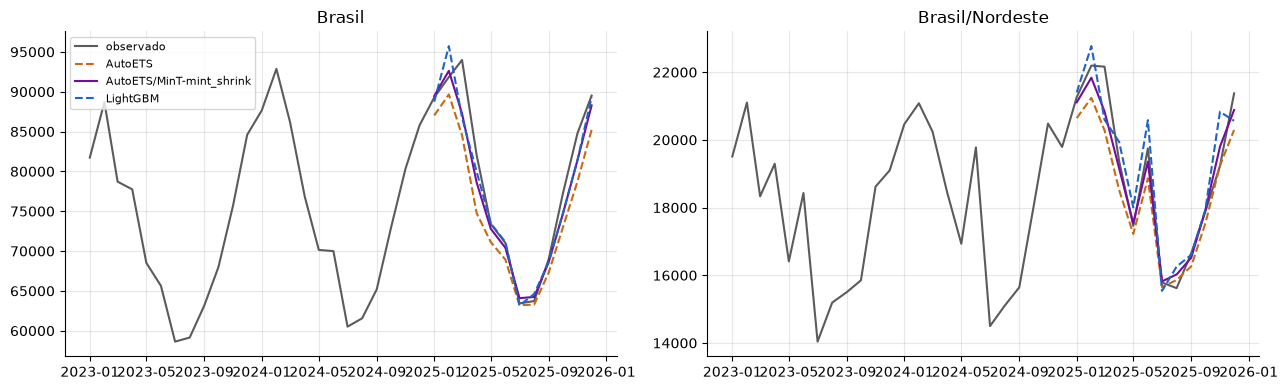

In [14]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
historico = Y_df[Y_df.ds >= "2023-01-01"].set_index(["unique_id", "ds"]).y
r = rec.set_index(["unique_id", "ds"])

for eixo, serie in zip(eixos, ["Brasil", "Brasil/Nordeste"]):
    h = historico.loc[serie]
    eixo.plot(h.index, h.values, color=CINZA, label="observado")
    for col, cor, estilo in [("AutoETS", LARANJA, "--"), ("AutoETS/MinT-mint_shrink", ROXO, "-"),
                             ("LightGBM", AZUL, "--")]:
        eixo.plot(r.loc[serie].index, r.loc[serie][col], color=cor, ls=estilo, label=col)
    eixo.set_title(serie)
eixos[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Modificações (escolham uma)

Editem a célula do passo que querem mudar e usem **Ambiente de execução → Executar depois**
(Ctrl+F10) a partir dela.

1. **Mais um modelo.** Acrescentem `AutoARIMA(season_length=12)` ao `StatsForecast`
   (lembrem de acrescentar `"AutoARIMA"` em `MODELOS`). Ele melhora algum nível?
2. **Features do LightGBM.** Tirem o `lag 12` e a diferença sazonal (`Differences([12])`).
   O modelo global continua bom? E se acrescentarem `RollingMean(window_size=6)`?
3. **Middle-out.** Acrescentem
   `MiddleOut(middle_level="total/regiao", top_down_method="forecast_proportions")`
   (de `hierarchicalforecast.methods`) à lista de reconciliadores. Onde ele fica entre o
   bottom-up e o top-down?
4. **SKU novo.** As séries `SA-*` (sem álcool) só existem desde mar/2022. Rodem a célula
   abaixo, que mede o MASE só dessas séries. Quem prevê melhor um produto com pouco histórico?

## Para mandar no chat

> Grupo X: modificação feita, melhor combinação no nível SKU **depois dela** (modelo + método)
> e o MASE, comparado com o original. Uma frase sobre o que mais surpreendeu.

In [15]:
# modificação 4: o MASE só dos SKUs sem álcool, os 8 melhores
from utilsforecast.evaluation import evaluate as avaliar_series

sa = rec[rec.unique_id.str.contains("SA-")].merge(teste, on=["unique_id", "ds"])
(avaliar_series(sa, metrics=[partial(mase, seasonality=12)],
                train_df=treino[treino.unique_id.str.contains("SA-")])
 .drop(columns=["unique_id", "metric"]).mean().sort_values().head(8).round(3))

LightGBM/MinT-ols            0.380
LightGBM/TopDown             0.429
LightGBM                     0.454
LightGBM/BottomUp            0.454
LightGBM/MinT-mint_shrink    0.455
AutoETS/MinT-mint_shrink     0.632
AutoETS/BottomUp             0.657
AutoETS                      0.657
dtype: float64